# Projeto Olist oportunidade de recompra

**Pergunta do projeto:** onde estão as oportunidades de recompra entre os clientes da Olist?

Começo examinando os arquivos, seus tipos de dados, valores ausentes e duplicatas. Essa exploração inicial ajuda a levantar hipóteses sobre como identificar pessoas e compras. Depois testo cada hipótese, observo os resultados e registro as decisões tomadas.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pasta = Path("OlistDados")

clientes = pd.read_csv(pasta / "olist_customers_dataset.csv")
pedidos = pd.read_csv(
    pasta / "olist_orders_dataset.csv",
    parse_dates=["order_purchase_timestamp"],
)

print(f"Cadastros de clientes: {len(clientes):,}")
print(f"Pedidos: {len(pedidos):,}")

Cadastros de clientes: 99,441
Pedidos: 99,441


## Exploração inicial dos dados

Antes de definir recompra, quero saber quais tabelas existem, quais campos têm valores ausentes, como os tipos foram lidos e onde há duplicatas. A presença de uma duplicata será investigada no contexto da tabela; ela não significa automaticamente um erro.

In [2]:

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

chaves = {
    "olist_customers_dataset.csv": ["customer_id"],
    "olist_geolocation_dataset.csv": None,
    "olist_order_items_dataset.csv": ["order_id", "order_item_id"],
    "olist_order_payments_dataset.csv": ["order_id", "payment_sequential"],
    "olist_order_reviews_dataset.csv": ["review_id", "order_id"],
    "olist_orders_dataset.csv": ["order_id"],
    "olist_products_dataset.csv": ["product_id"],
    "olist_sellers_dataset.csv": ["seller_id"],
    "product_category_name_translation.csv": ["product_category_name"],
}

resumo_tabelas = []
resumo_colunas = []

arquivos = sorted(pasta.glob("*.csv"))
print(f"Arquivos CSV encontrados: {len(arquivos)}")

for arquivo in arquivos:
    df = pd.read_csv(arquivo)
    original = pd.read_csv(arquivo, dtype=str, keep_default_na=False)
    chave = chaves.get(arquivo.name)

    resumo_tabelas.append({
        "tabela": arquivo.name,
        "linhas": len(df),
        "colunas": df.shape[1],
        "linhas_duplicadas": int(df.duplicated().sum()),
        "chave": ", ".join(chave) if chave else "não definida",
        "chaves_duplicadas": (
            int(df.duplicated(subset=chave).sum()) if chave else None
        ),
    })

    for coluna in df.columns:
        resumo_colunas.append({
            "tabela": arquivo.name,
            "coluna": coluna,
            "tipo": str(df[coluna].dtype),
            "nulos": int(df[coluna].isna().sum()),
            "vazios": int(original[coluna].str.strip().eq("").sum()),
            "nulos_%": round(df[coluna].isna().mean() * 100, 2),
        })

print("\nRESUMO DAS TABELAS")
display(pd.DataFrame(resumo_tabelas))

print("\nRESUMO DE TODAS AS COLUNAS")
display(pd.DataFrame(resumo_colunas))

Arquivos CSV encontrados: 9



RESUMO DAS TABELAS


,tabela,linhas,colunas,linhas_duplicadas,chave,chaves_duplicadas
0,olist_customers_dataset.csv,99441,5,0,customer_id,0.0
1,olist_geolocation_dataset.csv,1000163,5,261831,não definida,NaN
2,olist_order_items_dataset.csv,112650,7,0,"order_id, order_item_id",0.0
3,olist_order_payments_dataset.csv,103886,5,0,"order_id, payment_sequential",0.0
4,olist_order_reviews_dataset.csv,99224,7,0,"review_id, order_id",0.0
5,olist_orders_dataset.csv,99441,8,0,order_id,0.0
6,olist_products_dataset.csv,32951,9,0,product_id,0.0
7,olist_sellers_dataset.csv,3095,4,0,seller_id,0.0
8,product_category_name_translation.csv,71,2,0,product_category_name,0.0



RESUMO DE TODAS AS COLUNAS


,tabela,coluna,tipo,nulos,vazios,nulos_%
0,olist_customers_dataset.csv,customer_id,object,0,0,0.00
1,olist_customers_dataset.csv,customer_unique_id,object,0,0,0.00
2,olist_customers_dataset.csv,customer_zip_code_prefix,int64,0,0,0.00
3,olist_customers_dataset.csv,customer_city,object,0,0,0.00
4,olist_customers_dataset.csv,customer_state,object,0,0,0.00
5,olist_geolocation_dataset.csv,geolocation_zip_code_prefix,int64,0,0,0.00
6,olist_geolocation_dataset.csv,geolocation_lat,float64,0,0,0.00
7,olist_geolocation_dataset.csv,geolocation_lng,float64,0,0,0.00
8,olist_geolocation_dataset.csv,geolocation_city,object,0,0,0.00
9,olist_geolocation_dataset.csv,geolocation_state,object,0,0,0.00


**O que a exploração mostra:** os arquivos têm unidades diferentes. Existem tabelas de pedidos, itens, pagamentos e cadastros de clientes. Por isso, antes de contar recompras, preciso testar quais campos identificam uma pessoa e uma compra. As verificações de nulos e duplicatas também ficam registradas para orientar tratamentos futuros, quando cada coluna for usada.

## Hipóteses para definir recompra

**Hipótese 1:** `customer_id` identifica uma pessoa ao longo do tempo.  
**Por quê da hipótese:** preciso reconhecer a mesma pessoa em pedidos diferentes.

**Hipótese 2:** cada linha de uma tabela ligada a pedidos equivale a uma compra.  
**Por quê da hipótese:** preciso escolher a unidade correta para contar compras.

**Hipótese 3:** todo pedido registrado é uma compra concluída.  
**Por quê da hipótese:** preciso decidir quais status entram na análise.

**Hipótese 4:** todos os clientes podem ser comparados pelo mesmo prazo.  
**Por quê da hipótese:** clientes próximos ao fim da base podem ter menos tempo para voltar.

**Hipótese 5:** um segundo pedido em 90 dias representa uma nova ocasião de compra.  
**Por quê da hipótese:** pedidos quase simultâneos podem distorcer a interpretação de retenção.

**Hipótese 6:** a maior parte das novas compras depois de 24 horas acontece nos primeiros 30 dias.  
**Por quê da hipótese:** quero entender se existe um momento em que os clientes costumam voltar mais.

**Hipótese 7:** a recompra depois de 24 horas caiu em 2018.  
**Por quê da hipótese:** antes de comparar grupos de clientes, quero ver se a taxa muda com o período da primeira compra.

**Hipótese 8:** clientes que gastaram uma parte maior da primeira compra com frete voltam menos.  
**Por quê da hipótese:** quero ver se o peso do frete no primeiro pedido tem relação com a recompra.

**Hipótese 9:** clientes que gastaram mais em produtos na primeira compra voltam mais.  
**Por quê da hipótese:** no teste anterior, a parcela maior de frete apareceu em pedidos de produtos mais baratos. Quero separar o valor dos produtos do valor do frete para entender melhor esse resultado.

**Hipótese 10:** clientes que compraram mais itens no primeiro pedido voltam mais.  
**Por quê da hipótese:** quero testar se a quantidade de itens da primeira compra tem relação com a recompra, depois de olhar frete e valor.

**Hipótese 11:** a relação entre produtos diferentes na primeira compra e recompra aparece em períodos diferentes.  
**Por quê da hipótese:** quero conferir se o resultado anterior não veio só de alguns meses da base.

**Hipótese 12:** a diferença entre pedidos de um item e pedidos com produtos diferentes aparece mesmo quando comparo pedidos de valor parecido.  
**Por quê da hipótese:** quem compra produtos diferentes também costuma gastar mais. Quero ver se o sinal anterior depende só do valor da primeira compra.

## Hipótese 1: "customer_id" identifica uma pessoa ao longo do tempo?

Vou comparar os dois campos de identificação e procurar pessoas com vários cadastros.

In [3]:
resumo_clientes = pd.DataFrame({
    "medida": [
        "Linhas na tabela de clientes",
        "customer_id distintos",
        "customer_unique_id distintos",
        "customer_unique_id com mais de um customer_id",
    ],
    "quantidade": [
        len(clientes),
        clientes["customer_id"].nunique(),
        clientes["customer_unique_id"].nunique(),
        clientes.groupby("customer_unique_id")["customer_id"].nunique().gt(1).sum(),
    ],
})
display(resumo_clientes)

,medida,quantidade
0,Linhas na tabela de clientes,99441
1,customer_id distintos,99441
2,customer_unique_id distintos,96096
3,customer_unique_id com mais de um customer_id,2997


**Conclusão da hipótese 1:** Refutada. Os 99.441 "customer_id" são distintos, mas há 96.096 "customer_unique_id". 2.997 pessoas aparecem com mais de um cadastro. Portanto, "customer_id" serve para ligar pedido e cadastro, enquanto "customer_unique_id" é o campo para acompanhar a pessoa entre compras.

## Hipótese 2: Cada linha ligada a pedidos equivale a uma compra?

Vou comparar o número de linhas com o número de "order_id" distintos nas tabelas de pedidos, itens e pagamentos. Se houver vários registros por "order_id", contar linhas aumentará o número de compras.

In [4]:
itens = pd.read_csv(pasta / "olist_order_items_dataset.csv")
pagamentos = pd.read_csv(pasta / "olist_order_payments_dataset.csv")

unidade = []
for nome, tabela in [
    ("pedidos", pedidos),
    ("itens", itens),
    ("pagamentos", pagamentos),
]:
    unidade.append({
        "tabela": nome,
        "linhas": len(tabela),
        "order_id distintos": tabela["order_id"].nunique(),
        "pedidos com várias linhas": tabela["order_id"].value_counts().gt(1).sum(),
    })

display(pd.DataFrame(unidade))

,tabela,linhas,order_id distintos,pedidos com várias linhas
0,pedidos,99441,99441,0
1,itens,112650,98666,9803
2,pagamentos,103886,99440,2961


**Conclusão da hipótese 2:** Refutada. A tabela de itens tem 112.650 linhas, mas 98.666 pedidos distintos. Um pedido pode conter vários itens e pagamentos. A unidade de compra será o "order_id" da tabela de pedidos. A quantidade de itens não será confundida com recompra.

## Hipótese 3: Todo pedido registrado é uma compra concluída?

Vou observar a distribuição de "order_status". Se houver pedidos cancelados ou ainda em processamento, contar todos como compras concluídas mudaria a interpretação da métrica.

In [5]:
status = pedidos["order_status"].value_counts().rename_axis("status").reset_index(name="pedidos")
status["% dos pedidos"] = (status["pedidos"] / len(pedidos) * 100).round(2)
display(status)

,status,pedidos,% dos pedidos
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


**Conclusão da hipótese 3:** Refutada. Há pedidos cancelados, indisponíveis e em outros estados. Como a pergunta é sobre uma nova compra concluída, sigo apenas com "order_status == "delivered"". Essa escolha exclui pedidos não entregues, mesmo quando o cliente tentou comprar novamente.

## Hipótese 4: Todos os clientes podem ser comparados pelo mesmo prazo?

Uma pessoa que entrou no fim da base teve menos tempo para voltar. Vou inspecionar o volume mensal para identificar até quando os dados parecem completos antes de calcular uma taxa de recompra.

,mês,pedidos
0,2016-09,4
1,2016-10,324
2,2016-12,1
3,2017-01,800
4,2017-02,1780
5,2017-03,2682
6,2017-04,2404
7,2017-05,3700
8,2017-06,3245
9,2017-07,4026


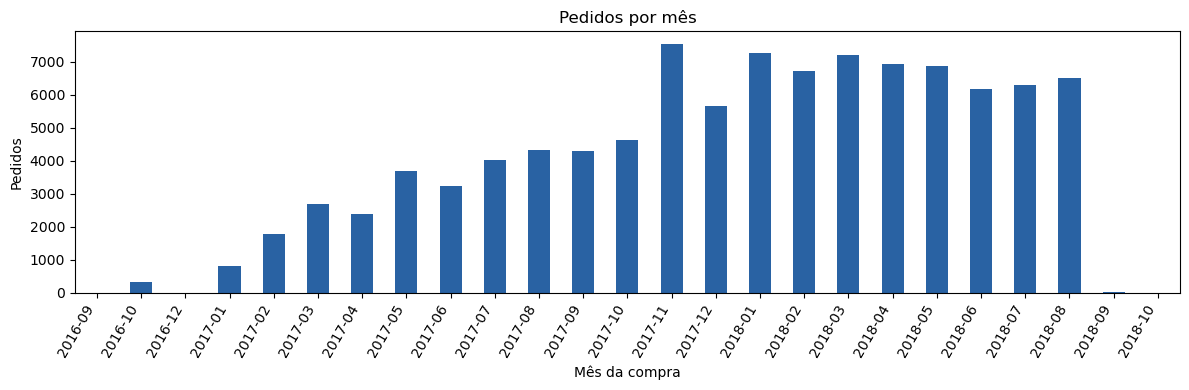

In [6]:
pedidos_mes = (
    pedidos.groupby(pedidos["order_purchase_timestamp"].dt.to_period("M"))
    .size()
    .rename("pedidos")
)
display(pedidos_mes.rename_axis("mês").reset_index())

fig, ax = plt.subplots(figsize=(12, 4))
pedidos_mes.plot(kind="bar", ax=ax, color="#2962a3")
ax.set(title="Pedidos por mês", xlabel="Mês da compra", ylabel="Pedidos")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

**Conclusão da hipótese 4:** Refutada. Agosto de 2018 tem 6.512 pedidos, enquanto setembro tem 16 e outubro tem 4. Esses meses finais não oferecem acompanhamento comparável. Vou encerrar a observação em **31/08/2018**. Para observar 90 dias completos, a primeira compra ocorrerá até **31/05/2018**. Começo em **01/01/2017**, pois 2016 tem poucos registros e um mês sem pedidos.

O corte é uma decisão metodológica baseada na cobertura de tempo que temos, não é uma propriedade natural dos clientes.

## Hipótese 5: Um segundo pedido em 90 dias representa uma nova compra?

Agora preciso ordenar as compras entregues de cada pessoa e medir o intervalo entre a primeira e a segunda. Se muitos segundos pedidos aconteceram no mesmo instante ou no mesmo dia, a hipótese de uma nova ocasião de compra fica fraca.

In [7]:
pedidos_pessoas = pedidos.merge(
    clientes[["customer_id", "customer_unique_id"]],
    on="customer_id", how="left", validate="many_to_one"
)

entregues = (
    pedidos_pessoas.loc[pedidos_pessoas["order_status"].eq("delivered")]
    .sort_values(["customer_unique_id", "order_purchase_timestamp", "order_id"])
    .copy()
)
entregues["numero_compra"] = entregues.groupby("customer_unique_id").cumcount() + 1

primeira = (
    entregues.loc[entregues["numero_compra"].eq(1),
                  ["customer_unique_id", "order_id", "order_purchase_timestamp"]]
    .rename(columns={
        "order_id": "primeiro_order_id",
        "order_purchase_timestamp": "data_primeira_compra",
    })
)
segunda = (
    entregues.loc[entregues["numero_compra"].eq(2),
                  ["customer_unique_id", "order_id", "order_purchase_timestamp"]]
    .rename(columns={
        "order_id": "segundo_order_id",
        "order_purchase_timestamp": "data_segunda_compra",
    })
)

base = primeira.merge(segunda, on="customer_unique_id", how="left", validate="one_to_one")
base["dias_ate_segunda"] = (
    base["data_segunda_compra"] - base["data_primeira_compra"]
).dt.total_seconds() / 86400

print(f"Pessoas com ao menos uma compra entregue: {len(base):,}")
print(f"Pessoas com ao menos duas compras entregues: {base['data_segunda_compra'].notna().sum():,}")
display(base["dias_ate_segunda"].dropna().describe(percentiles=[.25, .5, .75]).to_frame())

Pessoas com ao menos uma compra entregue: 93,358
Pessoas com ao menos duas compras entregues: 2,801


,dias_ate_segunda
count,2801.000000
mean,81.206685
std,110.004017
min,0.000000
25%,0.002130
50%,28.980197
75%,126.263588
max,608.978912


A distribuição já dá um sinal de alerta: o primeiro quartil do intervalo entre compras entregues é de poucos minutos. Antes de decidir como interpretar a taxa de 90 dias, vou medir quantas segundas compras estão concentradas nas primeiras 24 horas, usando apenas clientes com acompanhamento completo.

In [8]:
inicio_corte = pd.Timestamp("2017-01-01")
fim_coorte = pd.Timestamp("2018-05-31 23:59:59")
fim_observacao = pd.Timestamp("2018-08-31 23:59:59")

corte = base.loc[base["data_primeira_compra"].between(inicio_corte, fim_coorte)].copy()
segunda_observada = corte["data_segunda_compra"].le(fim_observacao)

faixas = pd.DataFrame({
    "intervalo": ["Mesmo segundo", "Até 1 hora", "Até 24 horas", "Mais de 24 horas até 90 dias"],
    "clientes": [
        int((segunda_observada & corte["dias_ate_segunda"].eq(0)).sum()),
        int((segunda_observada & corte["dias_ate_segunda"].between(0, 1 / 24)).sum()),
        int((segunda_observada & corte["dias_ate_segunda"].between(0, 1)).sum()),
        int((segunda_observada & corte["dias_ate_segunda"].gt(1)
             & corte["dias_ate_segunda"].le(90)).sum()),
    ],
})
total_90 = int((segunda_observada & corte["dias_ate_segunda"].between(0, 90)).sum())
faixas["% das recompras em 90 dias"] = (faixas["clientes"] / total_90 * 100).round(1)

print(f"Clientes com 90 dias de acompanhamento: {len(corte):,}")
print(f"Segundas compras em até 90 dias: {total_90:,}")
display(faixas)
print("As três primeiras faixas são acumuladas, não devem ser somadas.")

Clientes com 90 dias de acompanhamento: 75,123
Segundas compras em até 90 dias: 1,711


,intervalo,clientes,% das recompras em 90 dias
0,Mesmo segundo,213,12.4
1,Até 1 hora,737,43.1
2,Até 24 horas,781,45.6
3,Mais de 24 horas até 90 dias,930,54.4


As três primeiras faixas são acumuladas, não devem ser somadas.


**Conclusão da hipótese 5:** Refutada parcialmente. Das 1.711 segundas compras em até 90 dias, 781 (45,6%) aconteceram em até 24 horas, 213 têm o mesmo horário da primeira compra. São "order_id" distintos, mas os dados não demonstram que representam uma nova ocasião de compra para fins de retenção. Não vou chamar essa concentração de efeito de marketing.

**Decisão inicial:** manter a definição operacional escolhida de segundo pedido entregue em até 90 dias e registrar a limitação. Antes de recomendar ações de retenção, comparar a análise com uma versão que exclua compras até 24 horas.

## Como a janela de tempo escolhida altera o número observado?

Os **90 dias** são uma escolha de análise, não uma hipótese validada pelo dataset. Vou comparar 30, 60 e 90 dias no mesmo corte, mantendo o denominador constante. Isso mostra a sensibilidade da medida ao prazo.

In [9]:
comparacao = []
for prazo in [30, 60, 90]:
    recomprou = segunda_observada & corte["dias_ate_segunda"].between(0, prazo)
    comparacao.append({
        "prazo (dias)": prazo,
        "clientes elegíveis": len(corte),
        "clientes com segunda compra": int(recomprou.sum()),
        "taxa (%)": round(recomprou.mean() * 100, 2),
    })

display(pd.DataFrame(comparacao))

,prazo (dias),clientes elegíveis,clientes com segunda compra,taxa (%)
0,30,75123,1247,1.66
1,60,75123,1515,2.02
2,90,75123,1711,2.28


## Análise de sensibilidade: compras após as primeiras 24 horas

**Hipótese:** se pedidos quase simultâneos distorcem a ideia de retenção, exigir mais de 24 horas entre a primeira compra e uma nova compra deve mudar a taxa. Vou manter o mesmo corte e o mesmo prazo de 90 dias. Para não perder uma compra válida, procuro **qualquer pedido posterior a 24 horas**, mesmo quando o segundo pedido aconteceu antes disso.

In [10]:
pedidos_do_corte = entregues.merge(
    corte[["customer_unique_id", "data_primeira_compra"]],
    on="customer_unique_id", how="inner", validate="many_to_one"
)
pedidos_do_corte["dias_desde_primeira"] = (
    pedidos_do_corte["order_purchase_timestamp"]
    - pedidos_do_corte["data_primeira_compra"]
).dt.total_seconds() / 86400

recompras_apos_24h = pedidos_do_corte.loc[
    pedidos_do_corte["numero_compra"].gt(1)
    & pedidos_do_corte["dias_desde_primeira"].gt(1)
    & pedidos_do_corte["dias_desde_primeira"].le(90)
    & pedidos_do_corte["order_purchase_timestamp"].le(fim_observacao),
    "customer_unique_id",
].nunique()

comparacao_24h = pd.DataFrame({
    "regra": ["Segundo pedido em até 90 dias", "Nova compra após 24h e até 90 dias"],
    "clientes elegíveis": [len(corte), len(corte)],
    "clientes que recompraram": [total_90, recompras_apos_24h],
})
comparacao_24h["taxa (%)"] = (
    comparacao_24h["clientes que recompraram"]
    / comparacao_24h["clientes elegíveis"] * 100
).round(2)
display(comparacao_24h)

,regra,clientes elegíveis,clientes que recompraram,taxa (%)
0,Segundo pedido em até 90 dias,75123,1711,2.28
1,Nova compra após 24h e até 90 dias,75123,958,1.28


**Conclusão da análise de sensibilidade:** a taxa passa de **2,28%** (1.711 clientes) para **1,28%** (958 clientes) quando conto apenas novas compras feitas mais de 24 horas após a primeira. A diferença é de **753 clientes**. A definição original continua documentada, mas a leitura de oportunidades de retenção é sensível aos pedidos próximos no tempo. As duas medidas devem aparecer nas próximas análises.

## Hipótese 6: A maior parte das novas compras acontece nos primeiros 30 dias?

Agora vou olhar só para as novas compras feitas depois de 24 horas e dentro dos 90 dias. Para cada cliente, pego a primeira compra que atende a essa regra. Depois separo os intervalos de tempo para ver se o primeiro mês concentra a maior parte das voltas.

,tempo até a nova compra,clientes,% das novas compras,% acumulado
0,Mais de 1 até 7 dias,138,14.4,14.4
1,Mais de 7 até 30 dias,340,35.5,49.9
2,Mais de 30 até 60 dias,278,29.0,78.9
3,Mais de 60 até 90 dias,202,21.1,100.0


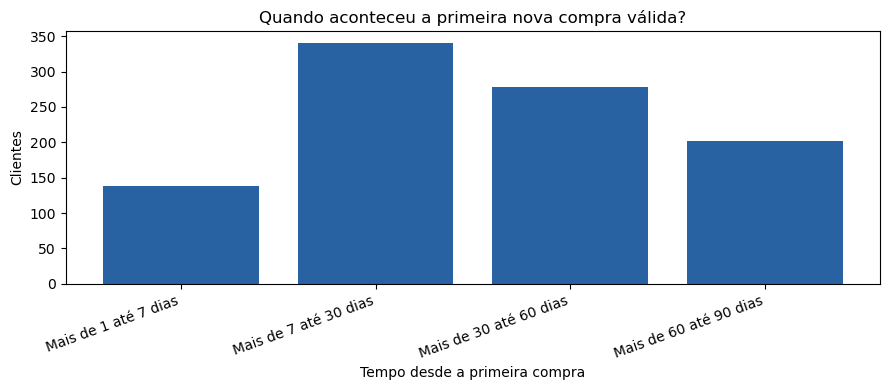

In [11]:
compras_validas = pedidos_do_corte.loc[
    pedidos_do_corte["numero_compra"].gt(1)
    & pedidos_do_corte["dias_desde_primeira"].gt(1)
    & pedidos_do_corte["dias_desde_primeira"].le(90)
    & pedidos_do_corte["order_purchase_timestamp"].le(fim_observacao)
].copy()

primeira_volta = (
    compras_validas
    .sort_values(["customer_unique_id", "order_purchase_timestamp", "order_id"])
    .drop_duplicates("customer_unique_id")
)

nomes_faixas = ["Mais de 1 até 7 dias", "Mais de 7 até 30 dias",
                "Mais de 30 até 60 dias", "Mais de 60 até 90 dias"]
contagem_faixas = pd.cut(
    primeira_volta["dias_desde_primeira"],
    bins=[1, 7, 30, 60, 90],
    labels=nomes_faixas,
).value_counts(sort=False)

tempo_ate_volta = pd.DataFrame({
    "tempo até a nova compra": nomes_faixas,
    "clientes": contagem_faixas.to_numpy(),
})
tempo_ate_volta["% das novas compras"] = (
    tempo_ate_volta["clientes"] / len(primeira_volta) * 100
).round(1)
tempo_ate_volta["% acumulado"] = (
    tempo_ate_volta["clientes"].cumsum() / len(primeira_volta) * 100
).round(1)

display(tempo_ate_volta)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(nomes_faixas, tempo_ate_volta["clientes"], color="#2962a3")
ax.set(title="Quando aconteceu a primeira nova compra válida?",
       xlabel="Tempo desde a primeira compra", ylabel="Clientes")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

**Conclusão da hipótese 6:** não encontrei uma maioria clara no primeiro mês. Dos 958 clientes que voltaram depois de 24 horas, 478 (49,9%) fizeram a nova compra em até 30 dias. Os outros 480 (50,1%) voltaram entre 30 e 90 dias.

Isso mostra que as voltas estão espalhadas pelo período. Ainda não dá para escolher um único momento para uma ação de retenção só com essa informação.

## Hipótese 7: A recompra depois de 24 horas caiu em 2018?

Vou calcular as duas taxas para cada mês da primeira compra. Também vou comparar janeiro a maio de 2017 com janeiro a maio de 2018. Assim, não comparo um ano inteiro com apenas cinco meses do outro. Além da taxa, vou mostrar quantos clientes entraram em cada mês.

,mes_primeira_compra,clientes,recompras_90d,recompras_apos_24h,taxa_90d_%,taxa_apos_24h_%
0,2017-01,717,26,6,3.63,0.84
1,2017-02,1628,28,15,1.72,0.92
2,2017-03,2503,62,32,2.48,1.28
3,2017-04,2256,48,29,2.13,1.29
4,2017-05,3451,98,55,2.84,1.59
5,2017-06,3037,86,43,2.83,1.42
6,2017-07,3752,97,48,2.59,1.28
7,2017-08,4057,112,58,2.76,1.43
8,2017-09,4004,114,71,2.85,1.77
9,2017-10,4328,97,53,2.24,1.22


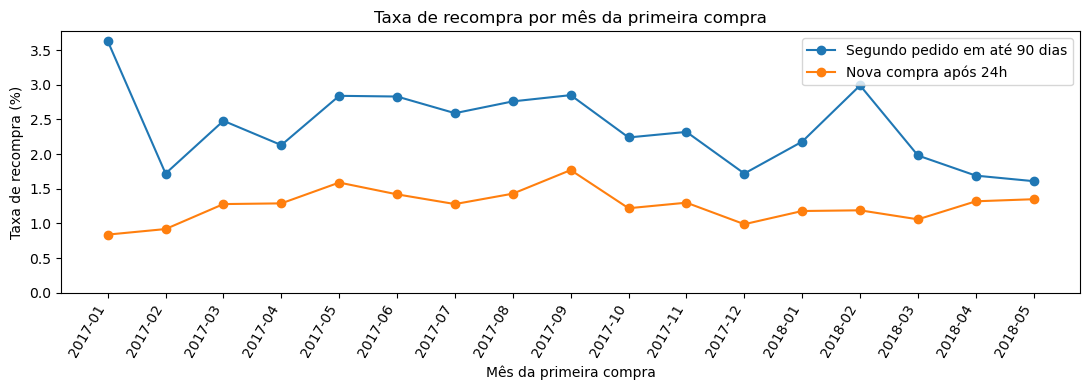

Comparação de janeiro a maio:


,ano,clientes,recompras_90d,recompras_apos_24h,taxa_90d_%,taxa_apos_24h_%
0,2017,10555,262,137,2.48,1.30
1,2018,32992,687,403,2.08,1.22


In [12]:
clientes_por_mes = corte[["customer_unique_id", "data_primeira_compra", "dias_ate_segunda"]].copy()
clientes_por_mes["mes_primeira_compra"] = clientes_por_mes["data_primeira_compra"].dt.to_period("M")
clientes_por_mes["recomprou_90d"] = (
    segunda_observada & corte["dias_ate_segunda"].between(0, 90)
)
clientes_por_mes["recomprou_apos_24h"] = (
    clientes_por_mes["customer_unique_id"].isin(primeira_volta["customer_unique_id"])
)

resumo_mensal = clientes_por_mes.groupby("mes_primeira_compra").agg(
    clientes=("customer_unique_id", "size"),
    recompras_90d=("recomprou_90d", "sum"),
    recompras_apos_24h=("recomprou_apos_24h", "sum"),
)
resumo_mensal["taxa_90d_%"] = (
    resumo_mensal["recompras_90d"] / resumo_mensal["clientes"] * 100
).round(2)
resumo_mensal["taxa_apos_24h_%"] = (
    resumo_mensal["recompras_apos_24h"] / resumo_mensal["clientes"] * 100
).round(2)

display(resumo_mensal.reset_index())

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(resumo_mensal.index.astype(str), resumo_mensal["taxa_90d_%"],
        marker="o", label="Segundo pedido em até 90 dias")
ax.plot(resumo_mensal.index.astype(str), resumo_mensal["taxa_apos_24h_%"],
        marker="o", label="Nova compra após 24h")
ax.set(title="Taxa de recompra por mês da primeira compra",
       xlabel="Mês da primeira compra", ylabel="Taxa de recompra (%)")
ax.set_ylim(bottom=0)
ax.legend()
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

meses_comparaveis = clientes_por_mes.loc[
    clientes_por_mes["data_primeira_compra"].dt.month.le(5)
].copy()
meses_comparaveis["ano"] = meses_comparaveis["data_primeira_compra"].dt.year

resumo_anos = meses_comparaveis.groupby("ano").agg(
    clientes=("customer_unique_id", "size"),
    recompras_90d=("recomprou_90d", "sum"),
    recompras_apos_24h=("recomprou_apos_24h", "sum"),
)
resumo_anos["taxa_90d_%"] = (
    resumo_anos["recompras_90d"] / resumo_anos["clientes"] * 100
).round(2)
resumo_anos["taxa_apos_24h_%"] = (
    resumo_anos["recompras_apos_24h"] / resumo_anos["clientes"] * 100
).round(2)

print("Comparação de janeiro a maio:")
display(resumo_anos.reset_index())

**Conclusão da hipótese 7:** houve uma queda pequena na taxa de recompra depois de 24 horas. Entre janeiro e maio, ela foi de **1,30% em 2017** e **1,22% em 2018**. A diferença é de **0,08 ponto percentual**. Pela regra do segundo pedido em até 90 dias, a taxa caiu de **2,48%** para **2,08%**.

Olhando mês a mês, a taxa oscila e o número de clientes também muda bastante. Por enquanto, não vejo uma queda forte na recompra depois de 24 horas. Nas próximas comparações, vou continuar mostrando o mês da primeira compra para não misturar diferenças de período com diferenças entre grupos de clientes.

## Hipótese 8: Uma parcela maior de frete está ligada a menos recompra?

Vou somar o valor dos produtos e do frete dos itens da primeira compra. Depois calculo a parte do total que foi frete e separo os clientes em quatro faixas com quantidades parecidas. Comparo as duas taxas de recompra em cada faixa.

Essa comparação mostra uma relação nos dados, se ela existir. Ela não mostra que o frete causou ou deixou de causar a volta do cliente.

Primeiros pedidos sem itens: 0
Primeiros pedidos com total zero: 0


,faixa_frete,clientes,parte_frete_mediana_%,produtos_mediana,frete_mediana,taxa_90d_%,taxa_apos_24h_%
0,Faixa 1: menor,18783,8.0,198.00,16.53,1.98,1.28
1,Faixa 2,18779,14.6,99.90,17.03,2.31,1.26
2,Faixa 3,18780,22.0,59.90,16.97,2.27,1.26
3,Faixa 4: maior,18781,35.7,29.99,16.79,2.56,1.30


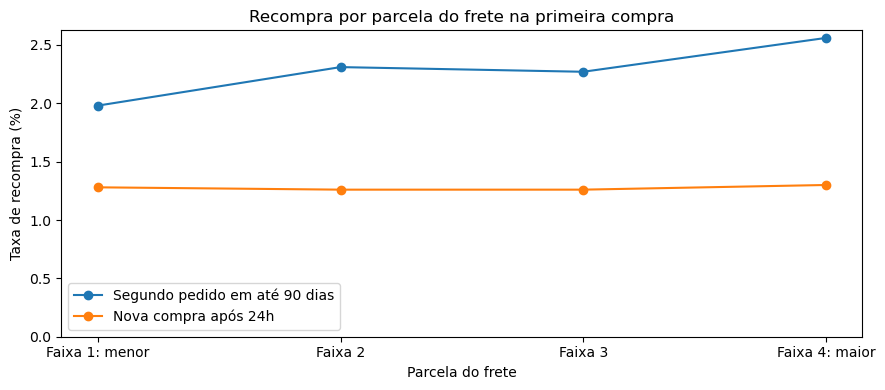

In [13]:
valores_primeiro_pedido = itens.groupby("order_id", as_index=False).agg(
    valor_produtos=("price", "sum"),
    valor_frete=("freight_value", "sum"),
)

analise_frete = corte[["customer_unique_id", "primeiro_order_id"]].merge(
    valores_primeiro_pedido,
    left_on="primeiro_order_id", right_on="order_id",
    how="left", validate="one_to_one",
)
analise_frete = analise_frete.merge(
    clientes_por_mes[["customer_unique_id", "recomprou_90d", "recomprou_apos_24h"]],
    on="customer_unique_id", how="left", validate="one_to_one",
)

analise_frete["total_pedido"] = (
    analise_frete["valor_produtos"] + analise_frete["valor_frete"]
)
analise_frete["parte_do_frete"] = (
    analise_frete["valor_frete"] / analise_frete["total_pedido"]
)

print(f"Primeiros pedidos sem itens: {analise_frete['valor_produtos'].isna().sum():,}")
print(f"Primeiros pedidos com total zero: {analise_frete['total_pedido'].eq(0).sum():,}")

nomes_frete = ["Faixa 1: menor", "Faixa 2", "Faixa 3", "Faixa 4: maior"]
analise_frete["faixa_frete"] = pd.qcut(
    analise_frete["parte_do_frete"], 4, labels=nomes_frete
)

resumo_frete = analise_frete.groupby("faixa_frete", observed=True).agg(
    clientes=("customer_unique_id", "size"),
    parte_frete_mediana=("parte_do_frete", "median"),
    produtos_mediana=("valor_produtos", "median"),
    frete_mediana=("valor_frete", "median"),
    recompras_90d=("recomprou_90d", "sum"),
    recompras_apos_24h=("recomprou_apos_24h", "sum"),
)
resumo_frete["parte_frete_mediana_%"] = (
    resumo_frete["parte_frete_mediana"] * 100
).round(1)
resumo_frete["taxa_90d_%"] = (
    resumo_frete["recompras_90d"] / resumo_frete["clientes"] * 100
).round(2)
resumo_frete["taxa_apos_24h_%"] = (
    resumo_frete["recompras_apos_24h"] / resumo_frete["clientes"] * 100
).round(2)

display(resumo_frete[[
    "clientes", "parte_frete_mediana_%", "produtos_mediana",
    "frete_mediana", "taxa_90d_%", "taxa_apos_24h_%"
]].reset_index())

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(nomes_frete, resumo_frete["taxa_90d_%"], marker="o",
        label="Segundo pedido em até 90 dias")
ax.plot(nomes_frete, resumo_frete["taxa_apos_24h_%"], marker="o",
        label="Nova compra após 24h")
ax.set(title="Recompra por parcela do frete na primeira compra",
       xlabel="Parcela do frete", ylabel="Taxa de recompra (%)")
ax.set_ylim(bottom=0)
ax.legend()
plt.tight_layout()
plt.show()

**Conclusão da hipótese 8:** não encontrei a queda que esperava. A taxa de recompra depois de 24 horas ficou entre **1,26% e 1,30%** nas quatro faixas. Pela regra do segundo pedido em até 90 dias, a taxa até sobe de **1,98%** na faixa mais baixa para **2,56%** na mais alta.

Na faixa com maior parcela de frete, o valor mediano dos produtos é bem menor, mas o frete mediano em reais é parecido com o das outras faixas. Ou seja, a porcentagem ficou maior principalmente porque o pedido era mais barato. Com esse teste, não tenho base para dizer que uma parcela maior de frete está ligada a menos recompra.

## Hipótese 9: Gastar mais na primeira compra está ligado a mais recompra?

No teste do frete, percebi que a porcentagem de frete subia quando o valor dos produtos caía. Agora vou olhar só para o valor dos produtos da primeira compra. Vou separar os clientes em quatro faixas com quantidades parecidas e comparar as duas taxas de recompra.

In [14]:
nomes_valor = ["Faixa 1: menor", "Faixa 2", "Faixa 3", "Faixa 4: maior"]
analise_frete["faixa_valor_produtos"] = pd.qcut(
    analise_frete["valor_produtos"], 4, labels=nomes_valor
)

resumo_valor = analise_frete.groupby("faixa_valor_produtos", observed=True).agg(
    clientes=("customer_unique_id", "size"),
    valor_mediano=("valor_produtos", "median"),
    recompras_90d=("recomprou_90d", "sum"),
    recompras_apos_24h=("recomprou_apos_24h", "sum"),
)
resumo_valor["taxa_90d_%"] = (
    resumo_valor["recompras_90d"] / resumo_valor["clientes"] * 100
).round(2)
resumo_valor["taxa_apos_24h_%"] = (
    resumo_valor["recompras_apos_24h"] / resumo_valor["clientes"] * 100
).round(2)

display(resumo_valor[[
    "clientes", "valor_mediano", "taxa_90d_%", "taxa_apos_24h_%"
]].reset_index())

,faixa_valor_produtos,clientes,valor_mediano,taxa_90d_%,taxa_apos_24h_%
0,Faixa 1: menor,18819,29.00,2.40,1.29
1,Faixa 2,18765,59.99,2.47,1.28
2,Faixa 3,18838,112.83,2.20,1.25
3,Faixa 4: maior,18701,230.98,2.04,1.28


**Conclusão da hipótese 9:** a hipótese não se confirmou. Mesmo com o valor mediano dos produtos indo de **R$ 29,00** na primeira faixa a **R$ 230,98** na última, a taxa de nova compra depois de 24 horas ficou entre **1,25% e 1,29%**.

Pela regra do segundo pedido em até 90 dias, a taxa cai de **2,40%** para **2,04%** entre as faixas menor e maior. Como esse desenho não aparece quando tiro as compras das primeiras 24 horas, o valor dos produtos não mostrou uma relação clara com a volta do cliente neste teste.

## Hipótese 10: Comprar mais itens na primeira vez está ligado a mais recompra?

Até aqui, frete e valor dos produtos não mostraram uma relação clara com a nova compra depois de 24 horas. Agora vou contar quantos itens havia no primeiro pedido de cada cliente. Vou comparar pedidos com um item, dois itens e três ou mais itens, mantendo as duas regras de recompra.

In [15]:
itens_por_pedido = itens.groupby("order_id", as_index=False).agg(
    qtd_itens=("product_id", "size"),
    qtd_produtos_diferentes=("product_id", "nunique"),
)

base_itens = corte[["customer_unique_id", "primeiro_order_id"]].merge(
    itens_por_pedido,
    left_on="primeiro_order_id", right_on="order_id",
    how="left", validate="one_to_one",
)
base_itens = base_itens.merge(
    clientes_por_mes[["customer_unique_id", "recomprou_90d", "recomprou_apos_24h"]],
    on="customer_unique_id", how="left", validate="one_to_one",
)

print(f"Primeiros pedidos sem itens: {base_itens['qtd_itens'].isna().sum():,}")

nomes_itens = ["1 item", "2 itens", "3 ou mais itens"]
base_itens["faixa_itens"] = pd.cut(
    base_itens["qtd_itens"], bins=[0, 1, 2, float("inf")], labels=nomes_itens
)

resumo_itens = base_itens.groupby("faixa_itens", observed=True).agg(
    clientes=("customer_unique_id", "size"),
    recompras_90d=("recomprou_90d", "sum"),
    recompras_apos_24h=("recomprou_apos_24h", "sum"),
)
resumo_itens["taxa_90d_%"] = (
    resumo_itens["recompras_90d"] / resumo_itens["clientes"] * 100
).round(2)
resumo_itens["taxa_apos_24h_%"] = (
    resumo_itens["recompras_apos_24h"] / resumo_itens["clientes"] * 100
).round(2)

display(resumo_itens.reset_index())

Primeiros pedidos sem itens: 0


,faixa_itens,clientes,recompras_90d,recompras_apos_24h,taxa_90d_%,taxa_apos_24h_%
0,1 item,67627,1458,826,2.16,1.22
1,2 itens,5782,181,91,3.13,1.57
2,3 ou mais itens,1714,72,41,4.20,2.39


A taxa sobe junto com a quantidade de itens, mas vários itens podem ser unidades do mesmo produto. Vou separar os primeiros pedidos com mais de um item em dois grupos: os que repetem um produto e os que têm produtos diferentes.

In [16]:
base_itens["tipo_primeiro_pedido"] = "1 item"
base_itens.loc[
    base_itens["qtd_itens"].ge(2) & base_itens["qtd_produtos_diferentes"].eq(1),
    "tipo_primeiro_pedido",
] = "2 ou mais itens do mesmo produto"
base_itens.loc[
    base_itens["qtd_produtos_diferentes"].ge(2),
    "tipo_primeiro_pedido",
] = "2 ou mais produtos diferentes"

ordem_tipos = [
    "1 item", "2 ou mais itens do mesmo produto", "2 ou mais produtos diferentes"
]
resumo_produtos = base_itens.groupby("tipo_primeiro_pedido").agg(
    clientes=("customer_unique_id", "size"),
    recompras_90d=("recomprou_90d", "sum"),
    recompras_apos_24h=("recomprou_apos_24h", "sum"),
).reindex(ordem_tipos)
resumo_produtos["taxa_90d_%"] = (
    resumo_produtos["recompras_90d"] / resumo_produtos["clientes"] * 100
).round(2)
resumo_produtos["taxa_apos_24h_%"] = (
    resumo_produtos["recompras_apos_24h"] / resumo_produtos["clientes"] * 100
).round(2)

display(resumo_produtos.reset_index())

,tipo_primeiro_pedido,clientes,recompras_90d,recompras_apos_24h,taxa_90d_%,taxa_apos_24h_%
0,1 item,67627,1458,826,2.16,1.22
1,2 ou mais itens do mesmo produto,5079,136,82,2.68,1.61
2,2 ou mais produtos diferentes,2417,117,50,4.84,2.07


**Conclusão da hipótese 10:** encontrei uma relação nos dados. A taxa de nova compra depois de 24 horas foi de **1,22%** para quem começou com um item, **1,57%** com dois itens e **2,39%** com três ou mais itens.

Quando separo os pedidos com vários itens, a taxa fica em **1,61%** para quem comprou mais unidades do mesmo produto e **2,07%** para quem comprou produtos diferentes. Isso ajuda a entender melhor o sinal, mas os grupos maiores em itens têm menos clientes. Por exemplo, o grupo de três ou mais itens teve **1.714 clientes e 41 novas compras** depois de 24 horas.

Por enquanto, posso dizer que existe uma associação entre a composição do primeiro pedido e a recompra. Não posso concluir que colocar mais itens no pedido faria o cliente voltar.

## Hipótese 11: O sinal de produtos diferentes aparece em períodos diferentes?

No teste anterior, quem começou com produtos diferentes teve uma taxa de recompra maior. Vou separar os clientes em três períodos e repetir a comparação. Também vou mostrar o número de recompras em cada grupo, porque uma taxa baseada em poucos casos pode variar bastante.

In [17]:
base_por_periodo = base_itens.merge(
    corte[["customer_unique_id", "data_primeira_compra"]],
    on="customer_unique_id", how="left", validate="one_to_one",
)

base_por_periodo["periodo"] = "Jun a dez/2017"
base_por_periodo.loc[
    base_por_periodo["data_primeira_compra"].between(
        "2017-01-01", "2017-05-31 23:59:59"
    ),
    "periodo",
] = "Jan a mai/2017"
base_por_periodo.loc[
    base_por_periodo["data_primeira_compra"].between(
        "2018-01-01", "2018-05-31 23:59:59"
    ),
    "periodo",
] = "Jan a mai/2018"

ordem_periodos = ["Jan a mai/2017", "Jun a dez/2017", "Jan a mai/2018"]
base_por_periodo["periodo"] = pd.Categorical(
    base_por_periodo["periodo"], categories=ordem_periodos, ordered=True
)
base_por_periodo["tipo_primeiro_pedido"] = pd.Categorical(
    base_por_periodo["tipo_primeiro_pedido"],
    categories=ordem_tipos, ordered=True,
)

resumo_por_periodo = base_por_periodo.groupby(
    ["periodo", "tipo_primeiro_pedido"], observed=True
).agg(
    clientes=("customer_unique_id", "size"),
    recompras_90d=("recomprou_90d", "sum"),
    recompras_apos_24h=("recomprou_apos_24h", "sum"),
)
resumo_por_periodo["taxa_90d_%"] = (
    resumo_por_periodo["recompras_90d"]
    / resumo_por_periodo["clientes"] * 100
).round(2)
resumo_por_periodo["taxa_apos_24h_%"] = (
    resumo_por_periodo["recompras_apos_24h"]
    / resumo_por_periodo["clientes"] * 100
).round(2)

display(resumo_por_periodo.reset_index())

,periodo,tipo_primeiro_pedido,clientes,recompras_90d,recompras_apos_24h,taxa_90d_%,taxa_apos_24h_%
0,Jan a mai/2017,1 item,9522,225,117,2.36,1.23
1,Jan a mai/2017,2 ou mais itens do mesmo produto,706,19,12,2.69,1.70
2,Jan a mai/2017,2 ou mais produtos diferentes,327,18,8,5.50,2.45
3,Jun a dez/2017,1 item,28433,657,372,2.31,1.31
4,Jun a dez/2017,2 ou mais itens do mesmo produto,2092,54,27,2.58,1.29
5,Jun a dez/2017,2 ou mais produtos diferentes,1051,51,19,4.85,1.81
6,Jan a mai/2018,1 item,29672,576,337,1.94,1.14
7,Jan a mai/2018,2 ou mais itens do mesmo produto,2281,63,43,2.76,1.89
8,Jan a mai/2018,2 ou mais produtos diferentes,1039,48,23,4.62,2.21


**Conclusão da hipótese 11:** o sinal de produtos diferentes apareceu nos três períodos. Pela regra de nova compra depois de 24 horas, a taxa desse grupo foi de **2,45%**, **1,81%** e **2,21%**. Para quem começou com um item, foi de **1,23%**, **1,31%** e **1,14%** nos mesmos períodos.

Isso dá mais força ao resultado anterior, mas ainda pede cuidado. No primeiro período, por exemplo, apenas **8 clientes** do grupo de produtos diferentes voltaram. O grupo com várias unidades do mesmo produto também não ficou acima do grupo de um item em todos os períodos. Por enquanto, o sinal mais consistente parece estar em começar com produtos diferentes, não apenas em ter mais itens.

## Hipótese 12: O sinal de produtos diferentes continua em pedidos de valor parecido?

Quem comprou produtos diferentes gastou mais na primeira compra, em média. Para não misturar as duas coisas, vou separar os pedidos em quatro faixas de valor e comparar os tipos de primeiro pedido dentro de cada faixa. Mostro clientes, recompras e taxas para não olhar só o percentual.

In [18]:
base_valor_produtos = base_itens.merge(
    analise_frete[["customer_unique_id", "valor_produtos"]],
    on="customer_unique_id", how="left", validate="one_to_one",
)

faixas_valor = ["Valor 1: menor", "Valor 2", "Valor 3", "Valor 4: maior"]
base_valor_produtos["faixa_valor"] = pd.qcut(
    base_valor_produtos["valor_produtos"], 4, labels=faixas_valor
)
base_valor_produtos["tipo_primeiro_pedido"] = pd.Categorical(
    base_valor_produtos["tipo_primeiro_pedido"],
    categories=ordem_tipos, ordered=True,
)

resumo_valor_e_produtos = base_valor_produtos.groupby(
    ["faixa_valor", "tipo_primeiro_pedido"], observed=True
).agg(
    clientes=("customer_unique_id", "size"),
    recompras_90d=("recomprou_90d", "sum"),
    recompras_apos_24h=("recomprou_apos_24h", "sum"),
)
resumo_valor_e_produtos["taxa_90d_%"] = (
    resumo_valor_e_produtos["recompras_90d"]
    / resumo_valor_e_produtos["clientes"] * 100
).round(2)
resumo_valor_e_produtos["taxa_apos_24h_%"] = (
    resumo_valor_e_produtos["recompras_apos_24h"]
    / resumo_valor_e_produtos["clientes"] * 100
).round(2)

display(resumo_valor_e_produtos.reset_index())

,faixa_valor,tipo_primeiro_pedido,clientes,recompras_90d,recompras_apos_24h,taxa_90d_%,taxa_apos_24h_%
0,Valor 1: menor,1 item,18081,435,234,2.41,1.29
1,Valor 1: menor,2 ou mais itens do mesmo produto,545,8,5,1.47,0.92
2,Valor 1: menor,2 ou mais produtos diferentes,193,8,3,4.15,1.55
3,Valor 2,1 item,17367,411,219,2.37,1.26
4,Valor 2,2 ou mais itens do mesmo produto,976,30,13,3.07,1.33
5,Valor 2,2 ou mais produtos diferentes,422,23,9,5.45,2.13
6,Valor 3,1 item,16777,343,194,2.04,1.16
7,Valor 3,2 ou mais itens do mesmo produto,1405,36,22,2.56,1.57
8,Valor 3,2 ou mais produtos diferentes,656,36,19,5.49,2.90
9,Valor 4: maior,1 item,15402,269,179,1.75,1.16


**Conclusão da hipótese 12:** o grupo que começou com produtos diferentes teve taxa de nova compra depois de 24 horas maior que o grupo de um item nas quatro faixas de valor. Isso mostra que o sinal anterior não desaparece quando comparo pedidos com valores parecidos.

Ainda preciso ter cuidado com os grupos pequenos. Na faixa de menor valor, só **3 clientes** do grupo de produtos diferentes voltaram. Também podem existir outras diferenças entre esses clientes que não medi aqui. Por isso, continuo tratando o resultado como associação, não como efeito de comprar mais produtos.

## O que esse resultado sugere para marketing?

Antes de pensar em uma ação, quero ver o tamanho dos grupos. Uma taxa maior em um grupo pequeno pode chamar atenção, mas o grupo de um item concentra muito mais clientes. Vou colocar volume e taxa lado a lado.

In [19]:
tamanho_grupos = resumo_produtos.reset_index()[[
    "tipo_primeiro_pedido", "clientes", "recompras_apos_24h",
    "taxa_apos_24h_%",
]].copy()
tamanho_grupos["% dos clientes do corte"] = (
    tamanho_grupos["clientes"] / len(corte) * 100
).round(1)

display(tamanho_grupos)

,tipo_primeiro_pedido,clientes,recompras_apos_24h,taxa_apos_24h_%,% dos clientes do corte
0,1 item,67627,826,1.22,90.0
1,2 ou mais itens do mesmo produto,5079,82,1.61,6.8
2,2 ou mais produtos diferentes,2417,50,2.07,3.2


**Leitura para marketing:** **67.627 clientes**, cerca de **90% do corte**, começaram com um item e tiveram taxa de nova compra depois de 24 horas de **1,22%**. O grupo que começou com produtos diferentes teve **2.417 clientes** e taxa de **2,07%**.

Isso aponta um grupo grande para **testar** uma ação de retenção depois da primeira compra. Uma ideia seria mostrar produtos complementares a clientes que compraram um item e comparar o resultado com um grupo que não recebeu a ação. Os dados atuais não mostram que essa ação funcionaria, nem permitem transformar a diferença de taxas em ganho esperado.

## O quê entendi nessa etapa

Um cliente recompra quando o mesmo "customer_unique_id" faz um segundo pedido distinto ("order_id") em até 90 dias após o horário da primeira compra. Os dois pedidos devem ter status "delivered".

**Corte:** primeira compra entregue feita de 01/01/2017 a 31/05/2018. **Final da observação:** 31/08/2018. O tempo entre compras é medido por "order_purchase_timestamp".

A hipótese de que todo segundo pedido representa retenção ficou fraca pelos pedidos quase simultâneos. A comparação com compras feitas após 24 horas mostrou uma taxa de 1,28%, frente a 2,28% pela regra original. Vou manter as duas medidas nas próximas análises para que as conclusões de marketing não dependam de um viés escondido.

Ao olhar o tempo das novas compras depois de 24 horas, vi que quase metade acontece até 30 dias e a outra metade entre 30 e 90 dias. Por enquanto, não encontrei um ponto único do período que concentre a maior parte das voltas.

Comparando janeiro a maio dos dois anos, a taxa depois de 24 horas ficou próxima: 1,30% em 2017 e 1,22% em 2018. A regra que conta o segundo pedido em até 90 dias mostrou uma diferença maior. Isso reforça por que mantenho as duas medidas visíveis e olho o período junto com qualquer comparação entre clientes.

Também testei o peso do frete na primeira compra. As quatro faixas tiveram taxas quase iguais quando contei apenas novas compras depois de 24 horas. A porcentagem de frete mais alta apareceu em pedidos de produtos mais baratos, e não em fretes medianos muito maiores. Essa hipótese não se confirmou nesse recorte.

Depois testei o valor dos produtos da primeira compra. A taxa depois de 24 horas ficou praticamente igual nas quatro faixas de valor. Então, neste corte, não encontrei sinal de que gastar mais na primeira compra esteja ligado a voltar mais.

A quantidade de itens trouxe o primeiro sinal mais claro dessa etapa. Clientes que começaram com mais itens tiveram taxas maiores de nova compra depois de 24 horas. Separei itens repetidos de produtos diferentes para entender melhor o grupo. Ainda trato isso como uma relação observada, não como prova de que aumentar o pedido causa recompra.

Conferi esse sinal por período. Clientes que começaram com produtos diferentes tiveram uma taxa maior que os de um item nos três períodos que comparei. Ainda preciso ter cuidado com os grupos menores e com outros fatores que podem estar por trás dessa diferença.

Separei os pedidos por faixa de valor e o grupo de produtos diferentes continuou com taxa maior que o de um item em todas as faixas. Mesmo assim, alguns grupos tiveram poucas recompras. A principal oportunidade para testar uma ação está no tamanho do grupo de um item: ele reúne cerca de 90% dos clientes do corte. Isso ainda é uma hipótese de marketing, não um ganho que eu possa prometer com esses dados.

## O que ainda não posso afirmar

Encontrei uma relação entre o tipo da primeira compra e a recompra, mas isso não prova que comprar produtos diferentes faz o cliente voltar. Esses clientes podem ser diferentes em outros pontos que não analisei. Além disso, o grupo de produtos diferentes é pequeno: foram **50 novas compras depois de 24 horas** entre **2.417 clientes**.

Os dados também não mostram campanhas, contatos com clientes ou custos de uma ação. Por isso, não consigo medir aqui o efeito de uma campanha nem calcular quanto ela traria de retorno financeiro.

## Uma ação que eu testaria

Minha ideia seria testar uma recomendação de produtos complementares para clientes que fizeram a primeira compra com **um item**. Esse é o maior grupo do corte e teve uma taxa de recompra menor. A diferença de taxas que encontrei **não é o ganho esperado** dessa ação.

Se a empresa pudesse fazer esse teste, eu dividiria esses clientes de forma aleatória em dois grupos depois da entrega do primeiro pedido. Um grupo receberia a recomendação; o outro não. Eu contaria apenas as novas compras feitas **depois do envio**, usando o mesmo prazo de acompanhamento para os dois grupos. Assim, poderia comparar as taxas e ver se a ação realmente ajudou.

Neste projeto, essa fica como **hipótese de ação**. A base da Olist permite encontrar o grupo e justificar o teste, mas não traz os dados necessários para executar ou medir essa campanha.

## Onde está a oportunidade de recompra?

Depois de testar as hipóteses, eu começaria pelos clientes cuja primeira compra teve **um item**. Eles são **67.627 pessoas, 90% do corte**, e tiveram taxa de nova compra após 24 horas de **1,22%**. É um grupo grande, com espaço para investigar se uma ação consegue trazer mais clientes de volta.

Quem começou com produtos diferentes teve uma taxa maior, de **2,07%**, mas representa só **2.417 pessoas**. Esse contraste me ajudou a encontrar o grupo que eu priorizaria para um teste. Ele não significa que eu consiga levar a taxa de um grupo até a do outro.

## O que os dados mostram e o que ainda precisa ser testado?

**O que os dados mostram:** a taxa geral de segundo pedido entregue em até 90 dias foi de **2,28%**. Quando considero qualquer nova compra entregue feita mais de 24 horas depois da primeira, ela fica em **1,28%**. O tipo do primeiro pedido também se relacionou com a taxa de nova compra neste corte. Esses são resultados observados nos dados.

**O que ainda precisa ser testado:** se recomendar produtos complementares depois da primeira entrega faz os clientes que compraram um item voltarem mais. Eu compararia um grupo que recebeu a recomendação com outro, escolhido de forma aleatória, que não recebeu. A base da Olist não tem informações de campanha para medir esse efeito agora. Por isso, a oportunidade é uma **ideia para teste**, não um resultado garantido.

## Conclusão geral

Após a análise, vi que a recompra foi pouco frequente no período observado: 2,28% dos clientes fizeram um segundo pedido em até 90 dias, e quase metade desses pedidos aconteceu nas primeiras 24 horas. Quando considero apenas novas compras depois desse intervalo, a taxa cai para 1,28%. Isso mostra que a forma de definir recompra muda bastante a leitura dos dados. Frete e valor da primeira compra não mostraram uma relação clara com a volta do cliente. O sinal mais interessante apareceu no tipo do primeiro pedido: quem comprou um item teve uma taxa menor e representa 90% dos clientes analisados. Por isso, esse é o grupo em que eu começaria a testar uma ação de marketing, sem tratar o resultado do teste como algo já comprovado pelos dados.